In [1]:
import os
import sys
from pathlib import Path
import yaml
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# 1. Project path setup
PROJECT_ROOT = Path(os.path.abspath(".."))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

# 2. Output directory for thesis figures
FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# 3. Device selection (Apple Silicon MPS / CPU)
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Computation device: {device}")

# 4. Academic Matplotlib aesthetics for thesis figures
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 13,
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "grid.linestyle": "--",
    "lines.linewidth": 1.75,
})

# Cohesive color palette for consistent model identity across all thesis figures
MODEL_COLORS = {
    "markowitz": "#1f77b4",       # Classical blue
    "markowitz_tc": "#ff7f0e",    # Cost-aware orange
    "il_conditioned": "#2ca02c",  # Conditioned IL green
    "rl_conditioned": "#d62728",  # Conditioned RL crimson
    "market": "#7f7f7f",          # Market benchmark gray
}

MODEL_LABELS = {
    "markowitz": "Classical Markowitz",
    "markowitz_tc": "Cost-Aware Markowitz",
    "il_conditioned": "Conditioned IL (DDIM)",
    "rl_conditioned": "Conditioned RL (DDIM)",
    "market": "Equal-Weight Market Index",
}

Computation device: mps


In [2]:
from simulator.loader import MarketDataLoader
from simulator.hmm import HybridJumpsHMM
from simulator.single_index import SingleIndexModel
from experts.markowitz import MarkowitzExpert
from agents.diffusion import MeanCovMLPDenoiser, PortDiff

# 1. Load system configuration
with open(PROJECT_ROOT / "config.yaml", "r") as f:
    config = yaml.safe_load(f)

market_ticker = config["data"]["market_ticker"]
stock_tickers = config["data"]["stock_tickers"]
n_assets = len(stock_tickers)
action_dim = n_assets + 1  # 50 stocks + 1 cash asset

window = config["expert"]["rolling_window"]
cost_c = config["expert"]["transaction_cost"]
risk_aversion = config["expert"]["risk_aversion"]
rf_rate = config["expert"]["annual_risk_free_rate"]

print(f"Configuration loaded: {n_assets} stocks, {window}-day window, cost {cost_c}")

# 2. Fetch market data and fit market simulator
loader = MarketDataLoader(
    tickers=[market_ticker] + stock_tickers,
    start_date=config["data"]["start_date"],
    end_date=config["data"]["end_date"]
)
data = loader.fetch_data()

hmm = HybridJumpsHMM(n_states=config["hmm"]["n_states"], emission_dist="gaussian")
hmm.fit(data[market_ticker])
hmm.epsilon = 0.0025
hmm.lambd = 85.0
print(f"HMM fitted with calibrated crash parameters: eps={hmm.epsilon}, lambda={hmm.lambd}")

sim_model = SingleIndexModel(tickers=stock_tickers, emission_dist="gaussian")
sim_model.fit(pd.DataFrame(data[stock_tickers]), data[market_ticker])
print("Single Index Model fitted successfully.")

# 3. Instantiate classical and cost-aware Markowitz experts
expert = MarkowitzExpert(
    risk_aversion=risk_aversion,
    rolling_window=window,
    max_weight=config["expert"]["max_weight"],
    annual_risk_free_rate=rf_rate,
    transaction_cost=0.0,
)

expert_tc = MarkowitzExpert(
    risk_aversion=risk_aversion,
    rolling_window=window,
    max_weight=config["expert"]["max_weight"],
    annual_risk_free_rate=rf_rate,
    transaction_cost=cost_c,
)
print("Classical and Cost-Aware Markowitz experts initialized.")

# 4. Load conditioned neural policies
il_denoiser = MeanCovMLPDenoiser(
    n_assets=n_assets,
    action_dim=action_dim,
    hidden_dim=1024,
    condition_on_prev_weights=True
)
il_model = PortDiff(denoiser=il_denoiser, num_timesteps=100, beta_schedule="linear")
il_path = PROJECT_ROOT / "il_conditioned.pth"
il_model.load_state_dict(torch.load(il_path, map_location=device))
il_model.to(device).eval()
print(f"Loaded Conditioned IL policy from {il_path.name}")

rl_denoiser = MeanCovMLPDenoiser(
    n_assets=n_assets,
    action_dim=action_dim,
    hidden_dim=1024,
    condition_on_prev_weights=True
)
rl_model = PortDiff(denoiser=rl_denoiser, num_timesteps=100, beta_schedule="linear")
rl_path = PROJECT_ROOT / "rl_conditioned.pth"
rl_model.load_state_dict(torch.load(rl_path, map_location=device))
rl_model.to(device).eval()
print(f"Loaded Conditioned RL policy from {rl_path.name}")

Configuration loaded: 10 stocks, 60-day window, cost 0.0005
HMM fitted with calibrated crash parameters: eps=0.0025, lambda=85.0
Single Index Model fitted successfully.
Classical and Cost-Aware Markowitz experts initialized.
Loaded Conditioned IL policy from il_conditioned.pth
Loaded Conditioned RL policy from rl_conditioned.pth


In [3]:
# 1. Trajectory simulation helper
def simulate_market_path(seed: int, n_steps: int = 2520):
    """
    Simulates asset returns, HMM regime states, and rolling observation windows.
    """
    np.random.seed(seed)
    sim_states = hmm.simulate_states(n_steps=n_steps, epsilon=hmm.epsilon, lambd=hmm.lambd)
    decoded_states = hmm.decode_states(sim_states)
    sim_stocks = sim_model.simulate(decoded_states, random_seed=seed)
    
    daily_rf = rf_rate / 252.0
    sim_stocks_with_cash = sim_stocks.copy()
    sim_stocks_with_cash["Cash"] = daily_rf
    actual_returns = sim_stocks_with_cash.to_numpy()[window:]  # (T, action_dim)
    
    stock_returns = sim_stocks.to_numpy()
    state_windows = np.array([
        stock_returns[t - window : t] for t in range(window, len(stock_returns))
    ])  # (T, window, n_assets)
    
    # Trim regime states to match evaluation horizon
    regime_states = sim_states[window:]
    
    return sim_stocks, state_windows, actual_returns, regime_states


# 2. Time-series metrics calculator accounting for drift
def evaluate_trajectory(weights_arr: np.ndarray, returns_arr: np.ndarray, cost_c: float = 0.0005):
    """
    Calculates dynamic daily performance series accounting for intra-period price drift.
    """
    T, action_dim = weights_arr.shape
    gross_returns = np.sum(weights_arr * returns_arr, axis=1)
    
    turnover = np.zeros(T)
    if T > 1:
        w_prev = weights_arr[:-1]
        r_prev = returns_arr[:-1]
        gross_prev = gross_returns[:-1, np.newaxis]
        drifted_w_prev = (w_prev * (1.0 + r_prev)) / np.maximum(1.0 + gross_prev, 1e-8)
        turnover[1:] = np.sum(np.abs(weights_arr[1:] - drifted_w_prev), axis=1)
    
    net_returns = gross_returns - cost_c * turnover
    cum_wealth = np.cumprod(1.0 + net_returns)
    running_max = np.maximum.accumulate(cum_wealth)
    drawdowns = (cum_wealth - running_max) / running_max
    cash_weights = weights_arr[:, -1]
    
    ann_net_ret = np.mean(net_returns) * 252.0
    ann_net_vol = np.std(net_returns) * np.sqrt(252.0) + 1e-9
    ann_gross_vol = np.std(gross_returns) * np.sqrt(252.0) + 1e-9
    net_sharpe = ann_net_ret / ann_net_vol
    gross_sharpe = (np.mean(gross_returns) * 252.0) / ann_gross_vol
    
    downside_vol = np.sqrt(np.mean(np.minimum(net_returns, 0.0)**2)) * np.sqrt(252.0) + 1e-9
    net_sortino = ann_net_ret / downside_vol
    max_dd = np.min(drawdowns)
    mean_turnover = np.mean(turnover[1:])
    
    return {
        "weights": weights_arr,
        "gross_returns": gross_returns,
        "net_returns": net_returns,
        "turnover": turnover,
        "cum_wealth": cum_wealth,
        "drawdowns": drawdowns,
        "cash_weights": cash_weights,
        "net_sharpe": net_sharpe,
        "gross_sharpe": gross_sharpe,
        "net_sortino": net_sortino,
        "ann_net_ret": ann_net_ret,
        "max_dd": max_dd,
        "mean_turnover": mean_turnover,
    }


# 3. Autoregressive rollout helper for neural policies
def rollout_policy(model, state_windows: np.ndarray, actual_returns: np.ndarray, sampler: str = "ddim"):
    """
    Rolls out a conditioned diffusion policy autoregressively with price drift tracking.
    """
    T = len(state_windows)
    prev_w = torch.zeros((1, action_dim), device=device)
    prev_w[0, -1] = 1.0  # Initial portfolio: 100% Cash
    
    weights_list = []
    model.eval()
    
    states_tensor = torch.tensor(state_windows, dtype=torch.float32, device=device)
    returns_tensor = torch.tensor(actual_returns, dtype=torch.float32, device=device)
    
    for t in range(T):
        st_t = states_tensor[t : t + 1]
        pw_t = prev_w.clone()
        with torch.no_grad():
            w_t = model.sample(st_t, prev_weights=pw_t, sampler=sampler)
            weights_list.append(w_t[0].cpu().numpy())
            
            # Intra-period price drift to period t end
            r_t = returns_tensor[t : t + 1]
            gross_ret = (w_t * r_t).sum(dim=1, keepdim=True)
            denom = torch.clamp(1.0 + gross_ret, min=1e-8)
            prev_w = (w_t * (1.0 + r_t)) / denom
            
    return np.array(weights_list)


# 4. Execute rollout on a representative crash seed
EVAL_SEED = 9005
print(f"Simulating identical trajectory for Seed {EVAL_SEED}...")
sim_stocks, state_windows, actual_returns, regime_states = simulate_market_path(EVAL_SEED)
T_eval = len(actual_returns)
crash_days = np.sum(regime_states == 2)
print(f"Horizon: {T_eval} days (~10 years). Severe crash regime days: {crash_days} ({crash_days / T_eval * 100:.1f}%)")

trajectories = {}

# A. Classical Markowitz
print("Running Classical Markowitz...")
w_markowitz = expert.generate_labels(sim_stocks, cost_aware=False).to_numpy()
trajectories["markowitz"] = evaluate_trajectory(w_markowitz, actual_returns, cost_c=cost_c)

# B. Cost-Aware Markowitz
print("Running Cost-Aware Markowitz...")
w_markowitz_tc = expert_tc.generate_labels(sim_stocks, cost_aware=True).to_numpy()
trajectories["markowitz_tc"] = evaluate_trajectory(w_markowitz_tc, actual_returns, cost_c=cost_c)

# C. Conditioned IL (DDIM)
print("Running Conditioned IL (DDIM)...")
w_il = rollout_policy(il_model, state_windows, actual_returns, sampler="ddim")
trajectories["il_conditioned"] = evaluate_trajectory(w_il, actual_returns, cost_c=cost_c)

# D. Conditioned RL (DDIM)
print("Running Conditioned RL (DDIM)...")
w_rl = rollout_policy(rl_model, state_windows, actual_returns, sampler="ddim")
trajectories["rl_conditioned"] = evaluate_trajectory(w_rl, actual_returns, cost_c=cost_c)

# E. Equal-Weight Market Benchmark (no cash, 1/N stocks)
w_market = np.zeros((T_eval, action_dim))
w_market[:, :-1] = 1.0 / n_assets
trajectories["market"] = evaluate_trajectory(w_market, actual_returns, cost_c=cost_c)

# 5. Display Trajectory Metrics Table
summary_rows = []
for k in ["markowitz", "markowitz_tc", "il_conditioned", "rl_conditioned", "market"]:
    traj = trajectories[k]
    summary_rows.append({
        "Model": MODEL_LABELS[k],
        "Net Sharpe": f"{traj['net_sharpe']:.4f}",
        "Gross Sharpe": f"{traj['gross_sharpe']:.4f}",
        "Net Return": f"{traj['ann_net_ret'] * 100:.2f}%",
        "Max Drawdown": f"{traj['max_dd'] * 100:.2f}%",
        "Daily Turnover": f"{traj['mean_turnover'] * 100:.2f}%",
    })

pd.DataFrame(summary_rows)

Simulating identical trajectory for Seed 9005...
Horizon: 2460 days (~10 years). Severe crash regime days: 73 (3.0%)
Running Classical Markowitz...
Running Cost-Aware Markowitz...
Running Conditioned IL (DDIM)...
Running Conditioned RL (DDIM)...


,Model,Net Sharpe,Gross Sharpe,Net Return,Max Drawdown,Daily Turnover
0,Classical Markowitz,0.4902,0.5793,11.48%,-50.09%,16.56%
1,Cost-Aware Markowitz,0.5127,0.5314,11.92%,-51.04%,3.46%
2,Conditioned IL (DDIM),0.5666,0.5901,13.20%,-53.51%,4.33%
3,Conditioned RL (DDIM),0.6064,0.6149,14.25%,-50.80%,1.59%
4,Equal-Weight Market Index,0.5190,0.5240,13.65%,-64.21%,1.04%


Saved thesis figures to:
  - /Users/emregulben/Desktop/portfolio_allocator/figures/crash_dynamics_4panel.pdf
  - /Users/emregulben/Desktop/portfolio_allocator/figures/crash_dynamics_4panel.png


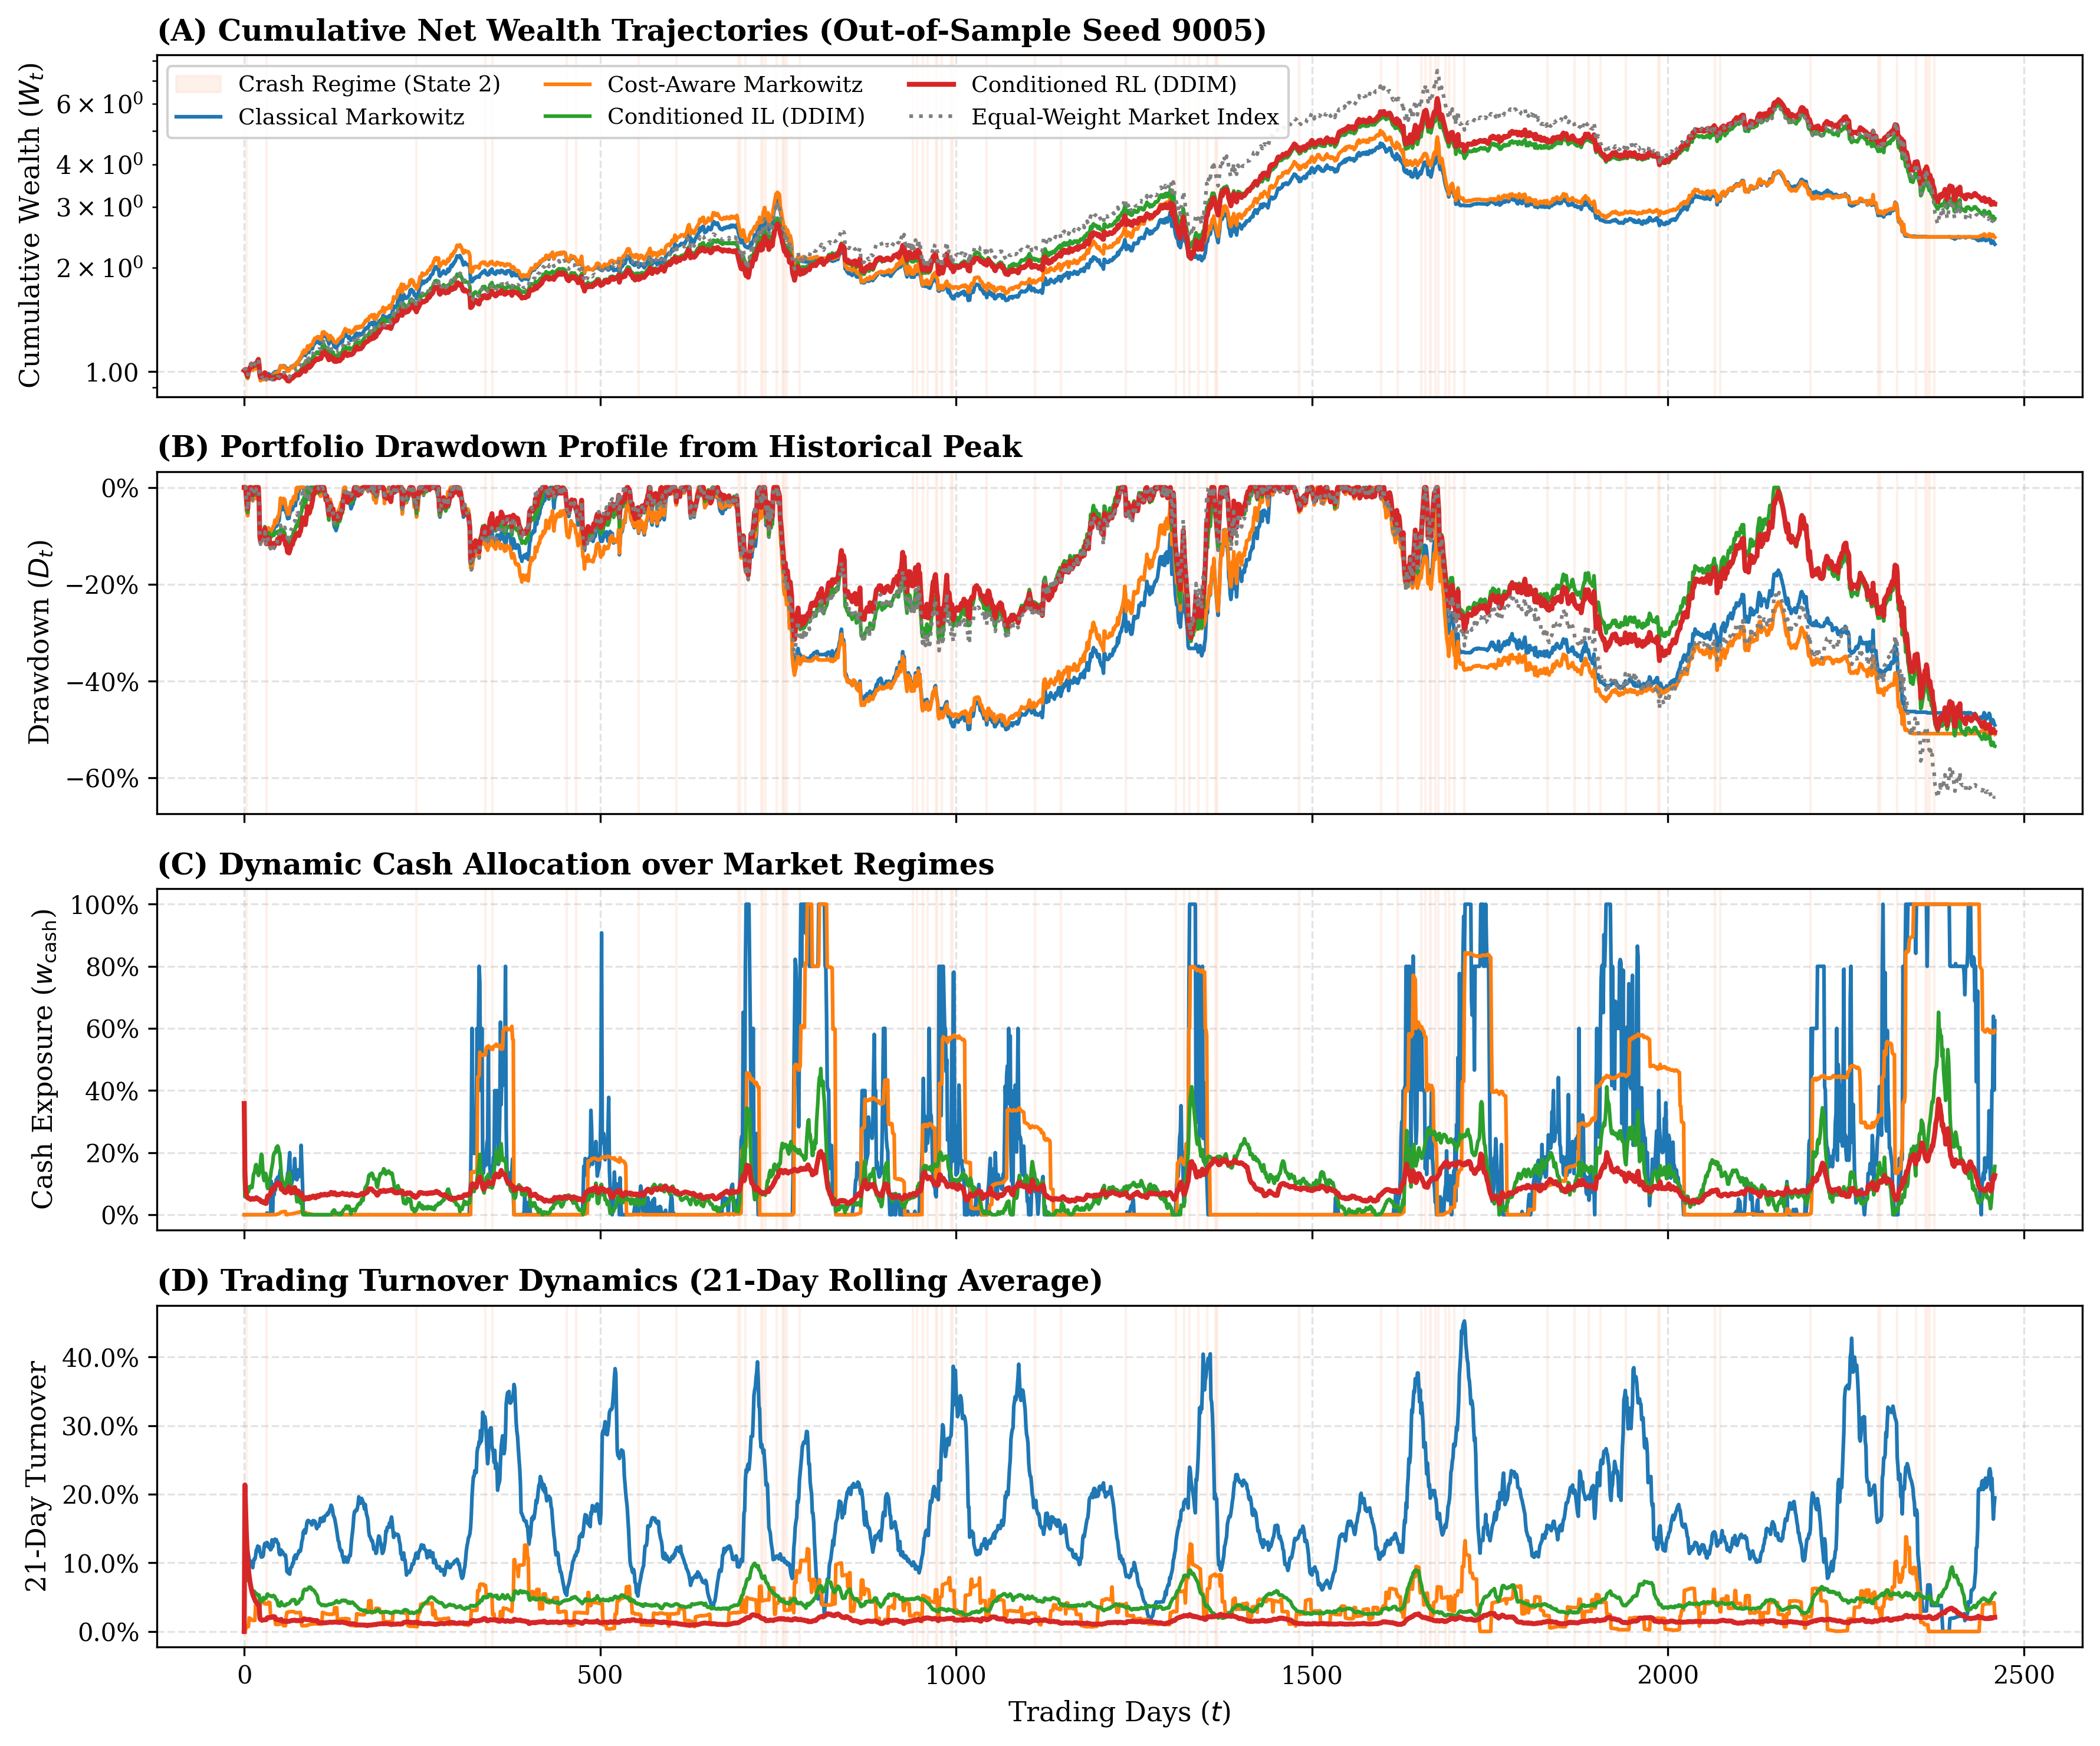

In [4]:
# Publication-Quality 4-Panel Trajectory Plot
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(12, 10), sharex=True, dpi=300)

t_axis = np.arange(T_eval)
models_to_plot = ["markowitz", "markowitz_tc", "il_conditioned", "rl_conditioned", "market"]

# Identify contiguous crash regime intervals (State 2)
crash_mask = (regime_states == 2)
crash_indices = np.where(crash_mask)[0]

def add_crash_shading(ax):
    """Adds subtle shading for HMM crash regime intervals."""
    if len(crash_indices) > 0:
        diffs = np.diff(crash_indices)
        split_points = np.where(diffs > 1)[0] + 1
        intervals = np.split(crash_indices, split_points)
        for idx, interval in enumerate(intervals):
            label = "Crash Regime (State 2)" if idx == 0 else None
            ax.axvspan(interval[0], interval[-1], color="#fee0d2", alpha=0.45, label=label, zorder=0)

# -------------------------------------------------------------
# Panel A: Cumulative Net Wealth
# -------------------------------------------------------------
ax_a = axes[0]
add_crash_shading(ax_a)
for k in models_to_plot:
    traj = trajectories[k]
    ls = ":" if k == "market" else "-"
    lw = 2.0 if k == "rl_conditioned" else 1.5
    ax_a.plot(t_axis, traj["cum_wealth"], label=MODEL_LABELS[k], color=MODEL_COLORS[k], linestyle=ls, linewidth=lw, zorder=3)

ax_a.set_ylabel("Cumulative Wealth ($W_t$)")
ax_a.set_title("(A) Cumulative Net Wealth Trajectories (Out-of-Sample Seed 9005)", loc="left", fontweight="bold")
ax_a.legend(loc="upper left", framealpha=0.9, ncol=3, fontsize=9)
ax_a.set_yscale("log")
ax_a.yaxis.set_major_formatter(mtick.ScalarFormatter())

# -------------------------------------------------------------
# Panel B: Drawdowns from Peak
# -------------------------------------------------------------
ax_b = axes[1]
add_crash_shading(ax_b)
for k in models_to_plot:
    traj = trajectories[k]
    ls = ":" if k == "market" else "-"
    lw = 2.0 if k == "rl_conditioned" else 1.5
    ax_b.plot(t_axis, traj["drawdowns"], label=MODEL_LABELS[k], color=MODEL_COLORS[k], linestyle=ls, linewidth=lw, zorder=3)

ax_b.set_ylabel("Drawdown ($D_t$)")
ax_b.set_title("(B) Portfolio Drawdown Profile from Historical Peak", loc="left", fontweight="bold")
ax_b.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

# -------------------------------------------------------------
# Panel C: Cash Allocation
# -------------------------------------------------------------
ax_c = axes[2]
add_crash_shading(ax_c)
for k in ["markowitz", "markowitz_tc", "il_conditioned", "rl_conditioned"]:
    traj = trajectories[k]
    lw = 2.0 if k == "rl_conditioned" else 1.5
    ax_c.plot(t_axis, traj["cash_weights"], label=MODEL_LABELS[k], color=MODEL_COLORS[k], linewidth=lw, zorder=3)

ax_c.set_ylabel("Cash Exposure ($w_{\\text{cash}}$)")
ax_c.set_title("(C) Dynamic Cash Allocation over Market Regimes", loc="left", fontweight="bold")
ax_c.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

# -------------------------------------------------------------
# Panel D: Daily Turnover Dynamics (21-Day Rolling Average)
# -------------------------------------------------------------
ax_d = axes[3]
add_crash_shading(ax_d)
turnover_window = 21
for k in ["markowitz", "markowitz_tc", "il_conditioned", "rl_conditioned"]:
    traj = trajectories[k]
    smoothed_turnover = pd.Series(traj["turnover"]).rolling(turnover_window, min_periods=1).mean()
    lw = 2.0 if k == "rl_conditioned" else 1.5
    ax_d.plot(t_axis, smoothed_turnover, label=MODEL_LABELS[k], color=MODEL_COLORS[k], linewidth=lw, zorder=3)

ax_d.set_ylabel("21-Day Turnover")
ax_d.set_xlabel("Trading Days ($t$)")
ax_d.set_title("(D) Trading Turnover Dynamics (21-Day Rolling Average)", loc="left", fontweight="bold")
ax_d.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

plt.tight_layout()

# Save vector PDF and high-res PNG for thesis
pdf_path = FIGURES_DIR / "crash_dynamics_4panel.pdf"
png_path = FIGURES_DIR / "crash_dynamics_4panel.png"
plt.savefig(pdf_path, bbox_inches="tight")
plt.savefig(png_path, bbox_inches="tight")
print(f"Saved thesis figures to:\n  - {pdf_path}\n  - {png_path}")
plt.show()

Saved refined zoom figures to:
  - /Users/emregulben/Desktop/portfolio_allocator/figures/crash_dynamics_zoom.pdf
  - /Users/emregulben/Desktop/portfolio_allocator/figures/crash_dynamics_zoom.png


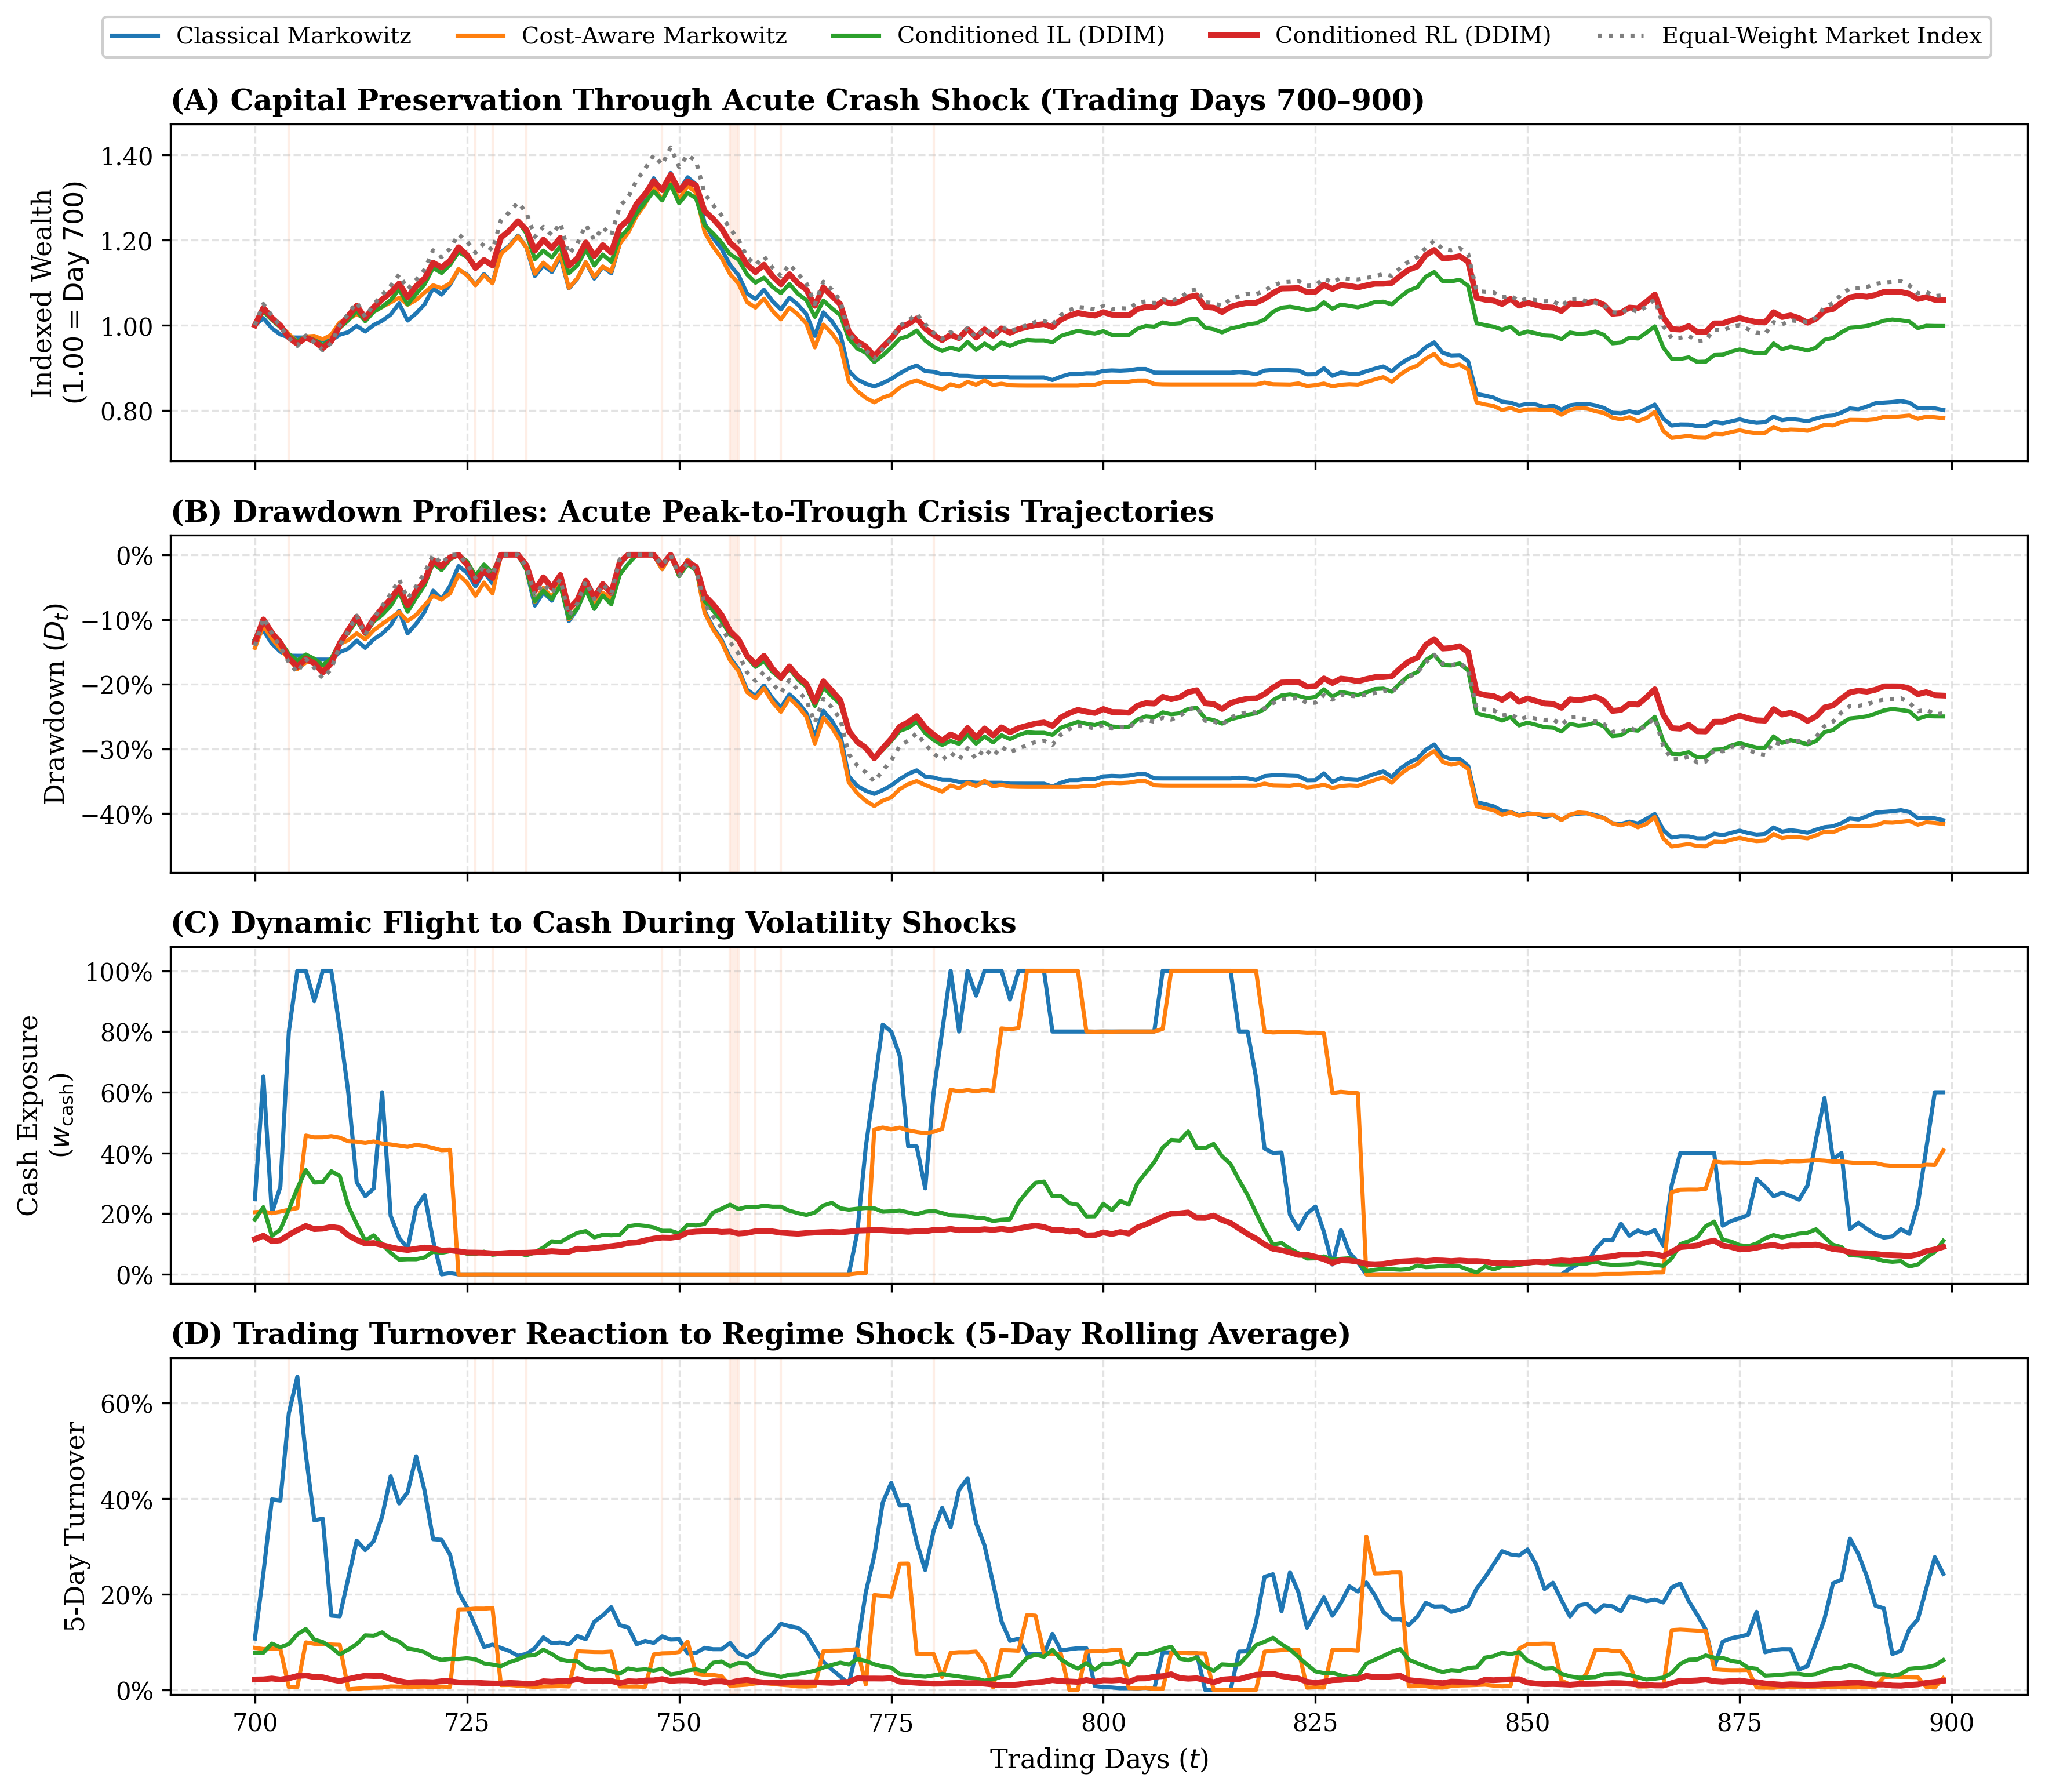

In [7]:
# ==============================================================================
# Block 5: Acute Crisis Event Study (Trading Days 700 to 900)
# ==============================================================================

zoom_start = 700
zoom_end = 900
t_zoom = np.arange(zoom_start, zoom_end)

fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(12, 10.5), sharex=True, dpi=300)

# Filter crash regime mask for the 200-day window
crash_zoom_mask = (regime_states[zoom_start:zoom_end] == 2)
crash_zoom_indices = np.where(crash_zoom_mask)[0] + zoom_start

def add_zoom_crash_shading(ax):
    if len(crash_zoom_indices) > 0:
        diffs = np.diff(crash_zoom_indices)
        split_points = np.where(diffs > 1)[0] + 1
        intervals = np.split(crash_zoom_indices, split_points)
        for idx, interval in enumerate(intervals):
            label = "Crash Regime (State 2)" if idx == 0 else None
            ax.axvspan(interval[0], interval[-1], color="#fee0d2", alpha=0.55, label=label, zorder=0)

models_order = ["markowitz", "markowitz_tc", "il_conditioned", "rl_conditioned", "market"]
legend_handles = []
legend_labels = []

# ------------------------------------------------------------------------------
# Panel A: Normalized Crisis Wealth (Indexed to 1.00 at Day 700)
# ------------------------------------------------------------------------------
ax_a = axes[0]
add_zoom_crash_shading(ax_a)

all_norm_wealth = []
for k in models_order:
    wealth_slice = trajectories[k]["cum_wealth"][zoom_start:zoom_end]
    norm_wealth = wealth_slice / wealth_slice[0]
    all_norm_wealth.append(norm_wealth)
    ls = ":" if k == "market" else "-"
    lw = 2.4 if k == "rl_conditioned" else 1.7
    line = ax_a.plot(t_zoom, norm_wealth, label=MODEL_LABELS[k], color=MODEL_COLORS[k], linestyle=ls, linewidth=lw, zorder=3)[0]
    legend_handles.append(line)
    legend_labels.append(MODEL_LABELS[k])

ax_a.set_ylabel("Indexed Wealth\n($1.00 = \\text{Day } 700$)")
ax_a.set_title("(A) Capital Preservation Through Acute Crash Shock (Trading Days 700–900)", loc="left", fontweight="bold")

# Dynamic Y-limits calculated from actual data with 8% headroom
min_w = min(np.min(w) for w in all_norm_wealth)
max_w = max(np.max(w) for w in all_norm_wealth)
pad_w = (max_w - min_w) * 0.08
ax_a.set_ylim(min_w - pad_w, max_w + pad_w)
ax_a.yaxis.set_major_formatter(mtick.FormatStrFormatter("%.2f"))

# ------------------------------------------------------------------------------
# Panel B: Drawdowns from Peak
# ------------------------------------------------------------------------------
ax_b = axes[1]
add_zoom_crash_shading(ax_b)

all_dds = []
for k in models_order:
    dd_slice = trajectories[k]["drawdowns"][zoom_start:zoom_end]
    all_dds.append(dd_slice)
    ls = ":" if k == "market" else "-"
    lw = 2.4 if k == "rl_conditioned" else 1.7
    ax_b.plot(t_zoom, dd_slice, color=MODEL_COLORS[k], linestyle=ls, linewidth=lw, zorder=3)

ax_b.set_ylabel("Drawdown ($D_t$)")
ax_b.set_title("(B) Drawdown Profiles: Acute Peak-to-Trough Crisis Trajectories", loc="left", fontweight="bold")
min_dd = min(np.min(d) for d in all_dds)
ax_b.set_ylim(min_dd - 0.04, 0.03)
ax_b.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

# ------------------------------------------------------------------------------
# Panel C: Dynamic Cash Allocation
# ------------------------------------------------------------------------------
ax_c = axes[2]
add_zoom_crash_shading(ax_c)

all_cash = []
for k in ["markowitz", "markowitz_tc", "il_conditioned", "rl_conditioned"]:
    cash_slice = trajectories[k]["cash_weights"][zoom_start:zoom_end]
    all_cash.append(cash_slice)
    lw = 2.4 if k == "rl_conditioned" else 1.7
    ax_c.plot(t_zoom, cash_slice, color=MODEL_COLORS[k], linewidth=lw, zorder=3)

ax_c.set_ylabel("Cash Exposure\n($w_{\\text{cash}}$)")
ax_c.set_title("(C) Dynamic Flight to Cash During Volatility Shocks", loc="left", fontweight="bold")
max_cash = max(np.max(c) for c in all_cash)
ax_c.set_ylim(-0.03, max(max_cash + 0.08, 0.40))
ax_c.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

# ------------------------------------------------------------------------------
# Panel D: 5-Day Rolling Turnover
# ------------------------------------------------------------------------------
ax_d = axes[3]
add_zoom_crash_shading(ax_d)

zoom_window = 5
all_to = []
for k in ["markowitz", "markowitz_tc", "il_conditioned", "rl_conditioned"]:
    turnover_full = pd.Series(trajectories[k]["turnover"])
    turnover_smoothed = turnover_full.rolling(zoom_window, min_periods=1).mean().to_numpy()
    turnover_slice = turnover_smoothed[zoom_start:zoom_end]
    all_to.append(turnover_slice)
    lw = 2.4 if k == "rl_conditioned" else 1.7
    ax_d.plot(t_zoom, turnover_slice, color=MODEL_COLORS[k], linewidth=lw, zorder=3)

ax_d.set_ylabel("5-Day Turnover")
ax_d.set_xlabel("Trading Days ($t$)")
ax_d.set_title("(D) Trading Turnover Reaction to Regime Shock (5-Day Rolling Average)", loc="left", fontweight="bold")
max_to = max(np.max(to) for to in all_to)
ax_d.set_ylim(-0.01, max_to + 0.04)
ax_d.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

# Adjust layout to leave dedicated space at the top for an outside legend
fig.subplots_adjust(top=0.92, bottom=0.06, left=0.08, right=0.97, hspace=0.22)

# Place the single legend completely outside above Panel A
fig.legend(
    handles=legend_handles,
    labels=legend_labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.985),
    ncol=5,
    frameon=True,
    framealpha=0.95,
    fontsize=9.5
)

# Save zoom figure to figures directory
zoom_pdf_path = FIGURES_DIR / "crash_dynamics_zoom.pdf"
zoom_png_path = FIGURES_DIR / "crash_dynamics_zoom.png"
plt.savefig(zoom_pdf_path, bbox_inches="tight")
plt.savefig(zoom_png_path, bbox_inches="tight")
print(f"Saved refined zoom figures to:\n  - {zoom_pdf_path}\n  - {zoom_png_path}")
plt.show()

/var/folders/4j/0zgkjz8d1tn5v2lg5ytlk4f00000gn/T/ipykernel_55520/1674920078.py:17: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", 20)


Saved asset allocation figures to:
  - /Users/emregulben/Desktop/portfolio_allocator/figures/asset_allocations_comparison.pdf
  - /Users/emregulben/Desktop/portfolio_allocator/figures/asset_allocations_comparison.png


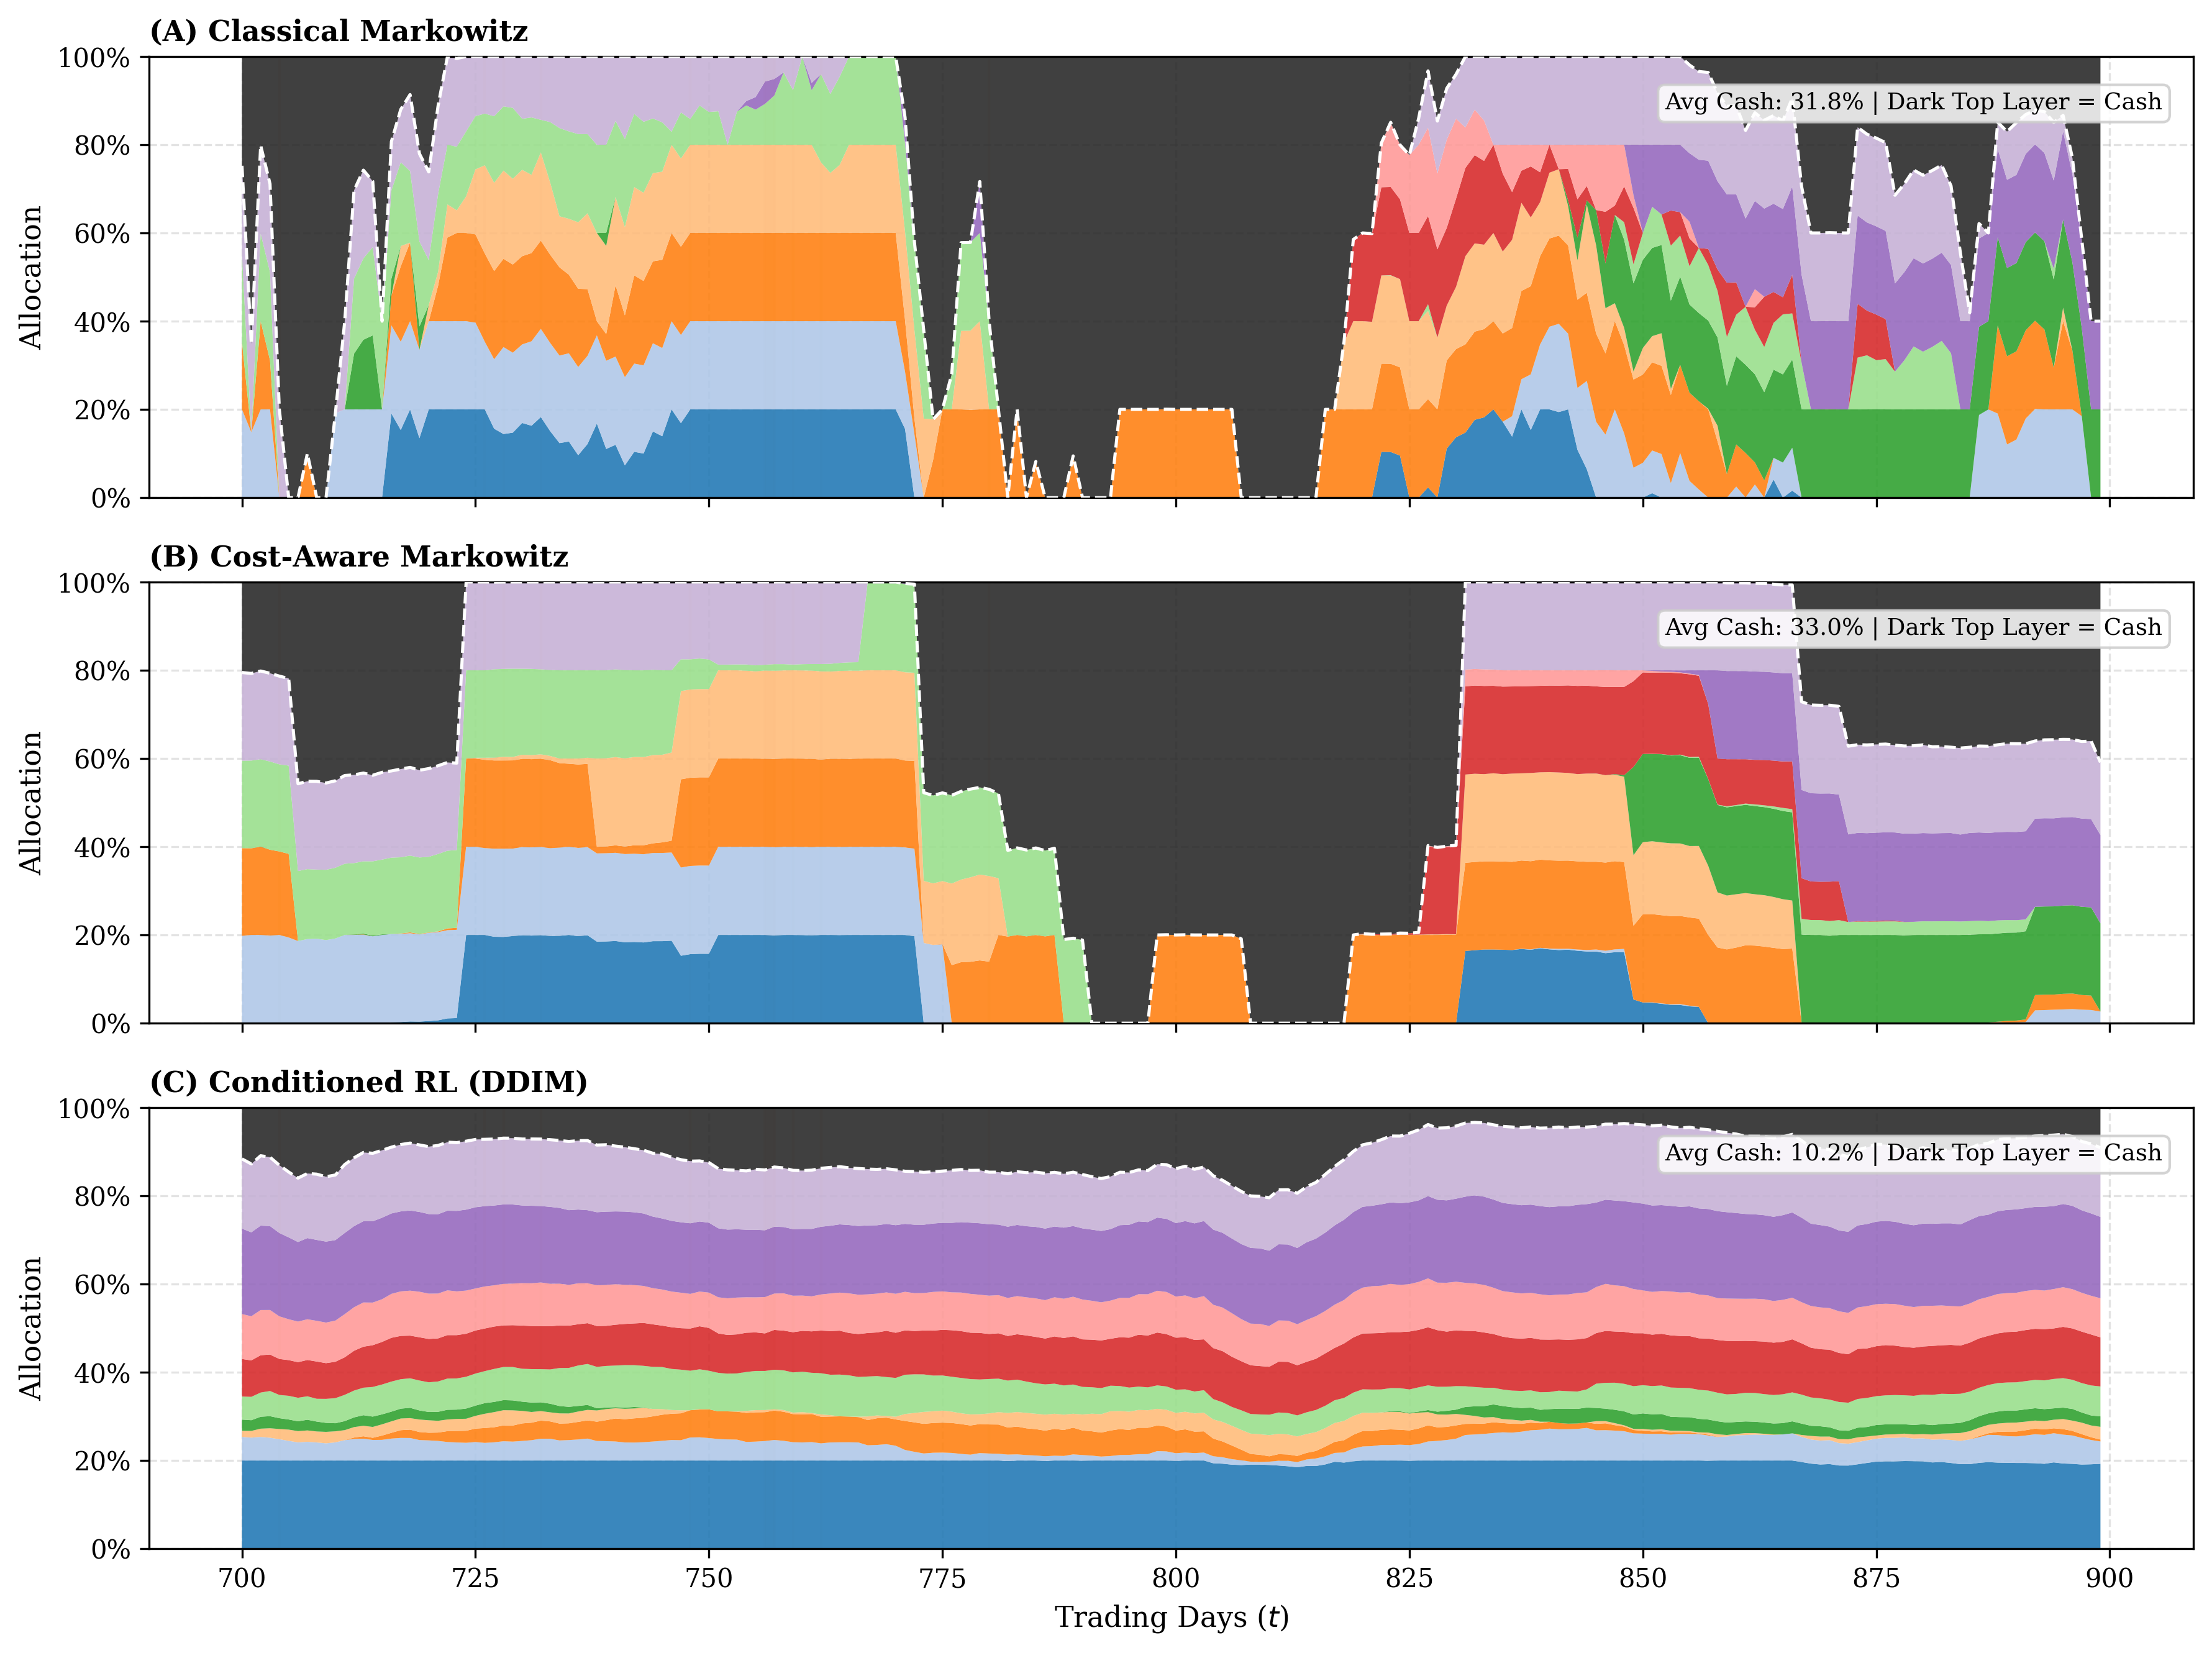

In [9]:
# ==============================================================================
# Block 6: Stacked Asset Allocation Dynamics (Classical vs. Cost-Aware vs. RL)
# ==============================================================================

plot_start = 700
plot_end = 900
t_alloc = np.arange(plot_start, plot_end)

models_alloc = [
    ("markowitz", "Classical Markowitz"),
    ("markowitz_tc", "Cost-Aware Markowitz"),
    ("rl_conditioned", "Conditioned RL (DDIM)"),
]

fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(12, 9), sharex=True, sharey=True, dpi=300)

cmap = plt.cm.get_cmap("tab20", 20)
stock_colors = [cmap(i % 20) for i in range(n_assets)]
cash_color = "#252525"

crash_alloc_mask = (regime_states[plot_start:plot_end] == 2)
crash_alloc_indices = np.where(crash_alloc_mask)[0] + plot_start

def add_alloc_crash_shading(ax):
    if len(crash_alloc_indices) > 0:
        diffs = np.diff(crash_alloc_indices)
        split_points = np.where(diffs > 1)[0] + 1
        intervals = np.split(crash_alloc_indices, split_points)
        for interval in intervals:
            ax.axvspan(interval[0], interval[-1], color="#fee0d2", alpha=0.4, zorder=1)

for idx, (m_key, title) in enumerate(models_alloc):
    ax = axes[idx]
    add_alloc_crash_shading(ax)
    
    w_slice = trajectories[m_key]["weights"][plot_start:plot_end]
    stocks_w = w_slice[:, :-1]
    cash_w = w_slice[:, -1]
    
    stacked_data = np.column_stack([stocks_w, cash_w]).T
    all_colors = stock_colors + [cash_color]
    
    ax.stackplot(t_alloc, stacked_data, colors=all_colors, alpha=0.88, zorder=2)
    
    equity_sum = np.sum(stocks_w, axis=1)
    ax.plot(t_alloc, equity_sum, color="white", linewidth=1.2, linestyle="--", zorder=3)
    
    ax.set_ylabel("Allocation")
    ax.set_title(f"({chr(65 + idx)}) {title}", loc="left", fontweight="bold", fontsize=11)
    ax.set_ylim(0.0, 1.0)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    
    mean_cash = np.mean(cash_w) * 100.0
    ax.text(
        0.985, 0.92,
        f"Avg Cash: {mean_cash:.1f}% | Dark Top Layer = Cash",
        transform=ax.transAxes,
        ha="right", va="top",
        fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.85, edgecolor="#ccc")
    )

axes[-1].set_xlabel("Trading Days ($t$)")
plt.tight_layout()

# Save vector PDF and PNG
alloc_pdf_path = FIGURES_DIR / "asset_allocations_comparison.pdf"
alloc_png_path = FIGURES_DIR / "asset_allocations_comparison.png"
plt.savefig(alloc_pdf_path, bbox_inches="tight")
plt.savefig(alloc_png_path, bbox_inches="tight")
print(f"Saved asset allocation figures to:\n  - {alloc_pdf_path}\n  - {alloc_png_path}")
plt.show()